# Lets have fun with building Decision Trees: You are building the decision tree classifier with the Scikit learn. Downlaod the data of Pima Indian diabetes from Kaggle. Feature Selection - you need to divide given columns into two types of variables dependent(or target variable) and independent variable(or feature variables). Split the data and then build decision tree. Use visualisation to showcase the pictorial representation. Find the Entropy, Information gain and Gini Index to support why you choose the specific root node

# Step 1 — Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2 — Load the dataset

In [2]:
df = pd.read_csv("DATA/diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Explanation

### - pd.read_csv() reads the CSV file.

### - df stores the dataset as a Pandas DataFrame.

### - df.head() displays the first five rows so we can inspect the data.

### Make sure the file path matches your actual folder structure. If diabetes.csv is in the same folder as your Python file, the path will be different.


## Conclusion

### The diabetes dataset is loaded, and its first five records are displayed for inspection.

# Step 3 — Check the dataset

In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

Dataset shape: (768, 9)

Column names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical summary:
       Pre

## Explanation

### - df.shape tells us the number of rows and columns.

### - df.columns displays all column names.

### -** df.info() shows data types and non-null counts.

### - df.describe() gives statistics such as mean, standard deviation, minimum and maximum.

## The standard dataset normally contains 768 rows and 9 columns, but we'll confirm that with your actual file.


## Conclusion

### This step helps us understand the dataset's structure and identify the variables before selecting the features and target.

# Step 4: Feature Selection — Independent and Dependent Variables

## In this step, we separate the dataset into independent variables (features) and a dependent variable (target).

### - **Independent variables (X):** These are the input columns used by the model to make predictions. In the Pima Indians Diabetes dataset, they include features such as Glucose, BMI, Age, BloodPressure, and Insulin.

### - **Dependent variable (y):** This is the column we want the model to predict. Here, the target variable is `Outcome`, where 0 represents no diabetes and 1 represents diabetes.We use the `drop()` function to remove the `Outcome` column from the features and store it separately as the target.

### This separation allows the Decision Tree Classifier to learn patterns from the input features and predict the target outcome.

In [4]:
# Independent variables (features)
X = df.drop("Outcome", axis=1)

# Dependent variable (target)
y = df["Outcome"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (768, 8)
Target shape: (768,)

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64



# Conclusion

## The dataset has been divided into independent and dependent variables. The independent variables will be used as inputs to train the Decision Tree Classifier, while the `Outcome` column will be used as the target for prediction.

# Step 5: Splitting the Dataset

## In this step, we divide the dataset into training and testing sets using the `train_test_split()` function from Scikit-learn.

### - **Training set (80%):** Used by the model to learn patterns from the data.

### - **Testing set (20%):** Used to evaluate how well the trained model predicts outcomes on data it has not seen during training.

### The `random_state=42` parameter makes the split reproducible, meaning we get the same split when we run the code again. The `stratify=y` parameter helps preserve the proportion of each target class in both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (614, 8)
Testing features: (154, 8)
Training targets: (614,)
Testing targets: (154,)



# Conclusion

## The dataset has been divided into training and testing sets. The training set will be used to build the Decision Tree Classifier, while the testing set will help us evaluate its predictive performance.

# Step 6: Building the Decision Tree Classifier

## In this step, we create and train a Decision Tree Classifier using Scikit-learn.

## A Decision Tree is a supervised machine learning algorithm that learns decision rules from the training data. It repeatedly splits the data based on feature values to help predict the target variable.

## We use `criterion="entropy"` to select splits based on entropy and information gain. Entropy measures the impurity or uncertainty in the target classes. Information gain measures how much that uncertainty decreases after a split.

## We set `max_depth=3` to limit the tree's depth, making it easier to visualize and understand. The model learns from the training features (`X_train`) and their corresponding target values (`y_train`).

In [6]:
# Create the Decision Tree Classifier
dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=42
)

# Train the model
dt.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!



# Conclusion

## The Decision Tree Classifier has been created and trained using the training dataset. The entropy criterion is used to select splits, and the maximum depth is limited to three levels to keep the tree easier to interpret.

# Step 7: Model Prediction and Evaluation

## After training the model, we use the testing dataset to predict the target variable. We then compare the predicted values with the actual values to evaluate the model's performance.

## We use the following evaluation measures:

### - **Accuracy:** The proportion of predictions that are correct.

### - **Confusion matrix:** Shows correct and incorrect predictions for each class.

### - **Classification report:** Displays precision, recall, and F1-score for each class.

### These measures help us understand how well the model performs on data that was not used for training.

In [7]:
# Predict outcomes using the testing data
y_pred = dt.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

Accuracy: 0.6948051948051948

Confusion Matrix:
[[92  8]
 [39 15]]

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.70      0.92      0.80       100
    Diabetes       0.65      0.28      0.39        54

    accuracy                           0.69       154
   macro avg       0.68      0.60      0.59       154
weighted avg       0.68      0.69      0.65       154




# Conclusion

## The trained model has been evaluated using the testing dataset. Accuracy, the confusion matrix, precision, recall, and F1-score provide different ways to assess its predictions.

# Step 8: Decision Tree Visualization

## In this step, we visualize the trained Decision Tree using Matplotlib and Scikit-learn's `plot_tree()` function.

## The visualization displays the feature used at each split, the decision threshold, the number of samples, and the class distribution. The tree starts at the root node and branches into smaller groups according to the learned rules.

## The colors help distinguish the predicted classes and the purity of the nodes. This visualization makes the model's decision-making process easier to understand.

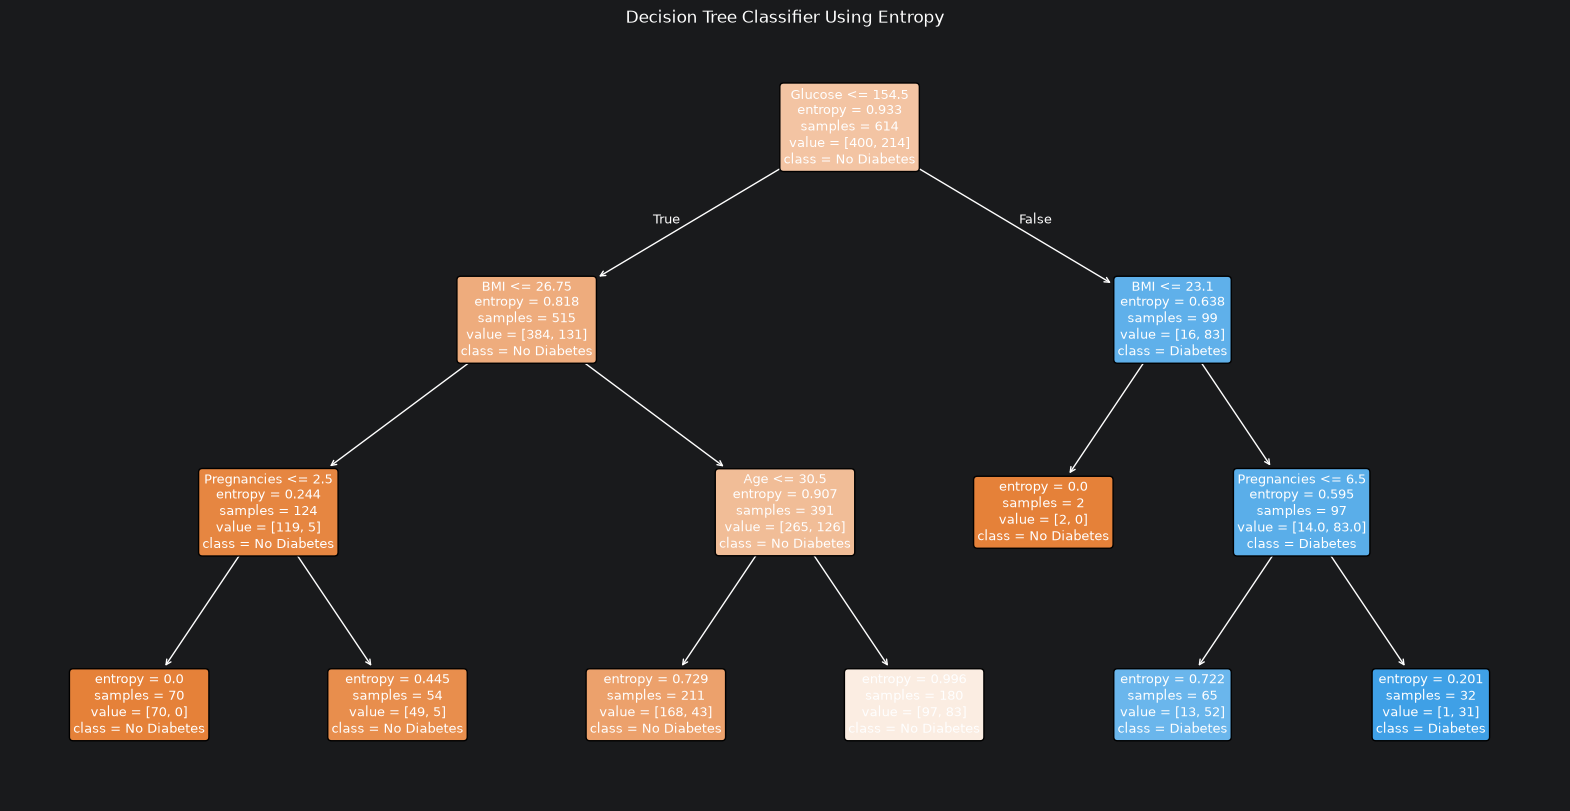

In [8]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classifier Using Entropy")
plt.show()


# Conclusion

## The trained Decision Tree has been visualized, showing its root node, decision rules, branches, and leaf nodes. The visualization helps explain how the model uses the input features to predict the target class.

# Step 9: Identifying the Root Node

## The root node is the first and topmost node of a Decision Tree. It represents the first feature used to split the dataset into smaller groups.

## The Decision Tree selects a splitting feature according to the chosen criterion. Since our model uses entropy, it searches for a split that provides high information gain, which means reducing uncertainty about the target variable.

## We can identify the selected root feature and its splitting threshold from the trained model.

In [9]:
# Identify the root feature
root_index = dt.tree_.feature[0]
root_threshold = dt.tree_.threshold[0]

if root_index >= 0:
    root_feature = X.columns[root_index]

    print("Root feature:", root_feature)
    print("Root threshold:", root_threshold)
    print(
        f"Root decision: {root_feature} <= "
        f"{root_threshold:.2f}"
    )
else:
    print("The root node is a leaf node.")

Root feature: Glucose
Root threshold: 154.5
Root decision: Glucose <= 154.50



# Conclusion

## The root feature and its threshold have been identified from the trained Decision Tree. The root feature represents the first split selected by the model using the entropy criterion.

# Step 10: Entropy, Information Gain, and Gini Index

## Entropy measures the uncertainty or impurity of the target classes. A lower entropy indicates that the classes are more concentrated in one category.

## Information Gain measures the reduction in entropy after splitting the dataset into child nodes. It is calculated by subtracting the weighted entropy of the child nodes from the entropy of the parent node.

## The Gini Index is another measure of impurity. A lower Gini Index indicates a purer node.

## In this step, we calculate the parent entropy, the weighted entropy after the root split, the information gain, the parent Gini Index, and the weighted Gini Index of the child nodes. These calculations help explain the quality of the selected split.

In [10]:
# Functions to calculate entropy and Gini impurity
def calculate_entropy(target):
    probabilities = target.value_counts(normalize=True)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


def calculate_gini(target):
    probabilities = target.value_counts(normalize=True)

    return 1 - np.sum(probabilities ** 2)


# Split the training data using the actual root rule
left_mask = X_train[root_feature] <= root_threshold

y_left = y_train[left_mask]
y_right = y_train[~left_mask]

# Parent and child entropy
parent_entropy = calculate_entropy(y_train)
left_entropy = calculate_entropy(y_left)
right_entropy = calculate_entropy(y_right)

# Weighted entropy of the child nodes
n = len(y_train)

weighted_child_entropy = (
    len(y_left) / n * left_entropy
    + len(y_right) / n * right_entropy
)

# Information Gain
information_gain = parent_entropy - weighted_child_entropy

# Parent and child Gini Index
parent_gini = calculate_gini(y_train)

left_gini = calculate_gini(y_left)
right_gini = calculate_gini(y_right)

weighted_child_gini = (
    len(y_left) / n * left_gini
    + len(y_right) / n * right_gini
)

print("Root feature:", root_feature)
print("Root threshold:", round(root_threshold, 4))

print("\n--- Entropy Calculations ---")
print("Parent Entropy:", round(parent_entropy, 4))
print("Left Child Entropy:", round(left_entropy, 4))
print("Right Child Entropy:", round(right_entropy, 4))
print("Weighted Child Entropy:", round(weighted_child_entropy, 4))
print("Information Gain:", round(information_gain, 4))

print("\n--- Gini Calculations ---")
print("Parent Gini Index:", round(parent_gini, 4))
print("Left Child Gini Index:", round(left_gini, 4))
print("Right Child Gini Index:", round(right_gini, 4))
print("Weighted Child Gini Index:", round(weighted_child_gini, 4))
print(
    "Gini Reduction:",
    round(parent_gini - weighted_child_gini, 4)
)

Root feature: Glucose
Root threshold: 154.5

--- Entropy Calculations ---
Parent Entropy: 0.9328
Left Child Entropy: 0.8181
Right Child Entropy: 0.6382
Weighted Child Entropy: 0.7891
Information Gain: 0.1436

--- Gini Calculations ---
Parent Gini Index: 0.4541
Left Child Gini Index: 0.3793
Right Child Gini Index: 0.271
Weighted Child Gini Index: 0.3619
Gini Reduction: 0.0923



# Conclusion

## The entropy and information gain calculations show how much uncertainty is reduced by the selected root split. The Gini Index provides an additional measure of impurity before and after the split.

## The model uses entropy to select its split, so information gain is the relevant selection measure for this tree. The Gini Index is included as an alternative measure for evaluating the split.

# Step 12: Interpretation of Entropy, Information Gain, and Gini Index

## The Decision Tree Classifier selected **Glucose** as its root feature, with a splitting threshold of 154.5.

## The parent entropy was 0.9328, while the weighted entropy of the child nodes was 0.7891. Therefore, the information gain was 0.1436, indicating that the selected split reduced uncertainty in the target variable.

## The parent Gini Index was 0.4541, and the weighted Gini Index after the split was 0.3619. The Gini reduction was 0.0923, showing that the split also reduced class impurity.

## These results indicate that the selected Glucose split improves the separation of the target classes. However, to prove that Glucose is the best root among all possible features and thresholds, we must compare its information gain with that of other candidate splits.

# Step 13: Comparing Candidate Root Splits

## A decision tree using entropy selects a split that maximizes information gain. To investigate the root selection, we compare the best information gain obtainable from different features in the training data.

## For each feature, we examine possible thresholds and calculate the parent entropy minus the weighted entropy of the resulting child nodes. The feature with the strongest candidate split provides a useful comparison with the root selected by the trained model.

In [11]:
def best_entropy_split(feature_values, target):
    data = pd.DataFrame({
        "feature": feature_values,
        "target": target
    }).sort_values("feature")

    values = data["feature"].to_numpy()
    labels = data["target"].to_numpy()

    parent_entropy = calculate_entropy(pd.Series(labels))
    best_gain = -1
    best_threshold = None

    # Consider midpoints between distinct feature values
    candidates = np.where(values[:-1] != values[1:])[0]

    for i in candidates:
        threshold = (values[i] + values[i + 1]) / 2

        left = labels <= -1  # placeholder, replaced below
        left = values <= threshold

        y_left = pd.Series(labels[left])
        y_right = pd.Series(labels[~left])

        weighted_entropy = (
            len(y_left) / len(labels) * calculate_entropy(y_left)
            + len(y_right) / len(labels) * calculate_entropy(y_right)
        )

        gain = parent_entropy - weighted_entropy

        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold

    return best_threshold, best_gain


results = []

for feature in X_train.columns:
    threshold, gain = best_entropy_split(
        X_train[feature],
        y_train
    )

    results.append({
        "Feature": feature,
        "Best Threshold": threshold,
        "Information Gain": gain
    })

comparison = pd.DataFrame(results).sort_values(
    "Information Gain",
    ascending=False
)

print(comparison.to_string(index=False))

                 Feature  Best Threshold  Information Gain
                 Glucose        154.5000          0.143640
                     BMI         29.6500          0.074059
                     Age         27.5000          0.065433
             Pregnancies          6.5000          0.038768
                 Insulin        128.5000          0.036772
DiabetesPedigreeFunction          0.5275          0.024315
           SkinThickness         32.5000          0.022859
           BloodPressure         69.0000          0.018507


# Conclusion

## In this practical, we successfully implemented a Decision Tree Classifier using Python and Scikit-learn on the Pima Indians Diabetes dataset.

## First, we separated the independent variables from the dependent variable, `Outcome`. We then divided the dataset into training and testing sets, trained the classifier using the entropy criterion, evaluated its predictions, and visualized the resulting decision tree.

## The model selected **Glucose** as the root feature with a threshold of **154.5**. The parent entropy was 0.9328, the weighted child entropy was 0.7891, and the information gain was 0.1436. The parent Gini Index was 0.4541, while the weighted child Gini Index was 0.3619, giving a Gini reduction of 0.0923.

## The comparison of candidate root splits also ranked Glucose first, supporting its selection as the root feature in this analysis. Finally, the decision tree visualization helped us understand how the model divides the data to predict the target class.

## Thus, this practical demonstrated feature selection, dataset splitting, decision tree classification, model evaluation, visualization, and the use of entropy, information gain, and Gini impurity to analyze decision tree splits.